# 1-05 사업 프로파일 — 이 회사는 뭘 팔고, 누구와 경쟁하나

**질문 예시:** "에코프로비엠 뭐 만들어서 파는 회사야? 매출 구성 보여줘", "삼성전자 사업 프로파일 정리해줘"

CHECK 원본(`1_기업펀더멘털/05_사업프로파일`)은 회사 소개·매출 구성·**시장 점유율**을 보여줬습니다.
DeepSearch로는 다음과 같이 만듭니다.

| 항목 | DeepSearch |
|---|---|
| 기본 정보 | `GetCompanySummary` (설립일·대표·업종·직원 수) |
| 사업 요약·현황 | `GetCompanyBusinessSummary` (사업보고서 요약 문장) |
| 매출 구성과 추이 | `GetCompanyProductsSales` (사업보고서 제품별 매출, 연간·분기 누적) |
| 관련 테마 | `GetEntityTags` (DeepSearch 주제 태그) |
| 같은 업종 상장사 | `GetStockSymbols`의 업종(`industry_name`) + 전 종목 시세 |
| 시장 점유율 | **구조화 데이터 없음** → 제목에 "점유율"이 들어간 증권사 리포트·뉴스를 찾아 보여줌 |

[![Colab에서 열기](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/beaten-by-the-market/deepsearch/blob/main/scenarios/1_fundamentals/05_business_profile.ipynb)

## 0. 준비
Colab 왼쪽 🔑(Secrets)에 `DEEPSEARCH_API_KEY`를 등록하고 이 노트북의 액세스를 켠 뒤 아래 두 셀을 실행하세요. 두 번째 셀은 모든 시나리오에 공통인 헬퍼입니다(접어 두어도 됩니다).

In [1]:
# Colab에서만: 한글 차트 폰트 설치 (로컬에서는 건너뜀)
import sys
if "google.colab" in sys.modules:
    !pip -q install koreanize-matplotlib

In [2]:
# ── DeepSearch 헬퍼 (모든 시나리오 노트북 공통) ─────────────────────────────
# Colab: 왼쪽 🔑(Secrets)에 이름 DEEPSEARCH_API_KEY 로 키를 넣고 "노트북 액세스"를 켜세요.
#        키는 "아이디:비밀번호" 형식이든 base64 문자열이든 됩니다. 키 값은 출력하지 않습니다.
# 로컬: 환경변수 DEEPSEARCH_API_KEY / API_KEY 또는 상위 폴더의 .env 를 읽습니다.
import base64, json, os, sys, time
from datetime import date, datetime, timedelta

import pandas as pd
import requests

IN_COLAB = "google.colab" in sys.modules
API_URL = "https://api.deepsearch.com/v1/compute"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)


def _norm_key(k):
    k = k.strip().strip('"').strip("'")
    return base64.b64encode(k.encode()).decode() if ":" in k else k


def _find_key():
    if IN_COLAB:
        try:
            from google.colab import userdata
            k = userdata.get("DEEPSEARCH_API_KEY")
            if k:
                return _norm_key(k)
        except Exception:
            pass
    for name in ("DEEPSEARCH_API_KEY", "API_KEY"):
        if os.environ.get(name):
            return _norm_key(os.environ[name])
    d = os.path.abspath(os.getcwd())
    while True:
        p = os.path.join(d, ".env")
        if os.path.isfile(p):
            for line in open(p, encoding="utf-8-sig"):
                if "=" in line and not line.strip().startswith("#"):
                    k, v = line.split("=", 1)
                    if k.strip() in ("DEEPSEARCH_API_KEY", "API_KEY") and v.strip():
                        return _norm_key(v)
        if os.path.dirname(d) == d:
            break
        d = os.path.dirname(d)
    from getpass import getpass
    return _norm_key(getpass("DeepSearch API 키: "))


_KEY = _find_key()


class DSError(Exception):
    pass


def ds(query, timeout=180, retries=3):
    """compute 호출 → 응답 JSON. 서버가 돌려준 오류(data.exceptions)는 DSError."""
    last = None
    for i in range(retries):
        try:
            r = requests.post(API_URL, json={"input": query}, timeout=timeout,
                              headers={"Authorization": "Basic " + _KEY})
            body = r.json()
        except Exception as e:  # 네트워크·일시 오류만 재시도
            last = e
            time.sleep(3 * (i + 1))
            continue
        exc = (body.get("data") or {}).get("exceptions") or []
        if exc or r.status_code >= 400:
            msg = "; ".join(f"{x.get('class', '')}: {' '.join(map(str, x.get('args') or [x.get('message', '')]))}"
                            if isinstance(x, dict) else str(x) for x in exc)
            raise DSError(f"{r.status_code} {msg or body}"[:500])
        return body
    raise DSError(f"요청 실패: {last}")


def _pod(body):
    pods = (body.get("data") or {}).get("pods") or []
    return pods[1] if len(pods) >= 2 else {}


def ds_df(query, **kw):
    """DataFrame 결과(재무·시세·경제지표 등) → pandas DataFrame. 결과가 없으면 빈 DataFrame."""
    c = _pod(ds(query, **kw)).get("content") or {}
    data = c.get("data") if isinstance(c, dict) else None
    if not isinstance(data, dict) or not data:
        return pd.DataFrame()
    cols = [x for x in (c.get("columns") or data.keys()) if x in data]
    df = pd.DataFrame({x: data[x] for x in cols})
    for x in ("date", "created_at"):
        if x in df and df[x].dtype == object:
            df[x] = pd.to_datetime(df[x].astype(str).str[:19], errors="coerce")
    return df


def _polarity(x):
    """문서 긍부정: polarity.name, 없으면 customized_ml.kis 모델 값(최근 뉴스는 절반가량이 이쪽에만 있음)."""
    p = x.get("polarity")
    if isinstance(p, dict) and p.get("name"):
        return p["name"]
    k = (((x.get("customized_ml") or {}).get("kis") or {}).get("ip_multitask") or {}).get("polarity") or {}
    return k.get("name")


def doc_search(category, section, query, date_from, date_to, count=100, pages=1):
    """DocumentSearch → (총건수, 문서 DataFrame). category: news/research/company/patent. 기간은 1년 이내.
    종목 지정은 securities.symbol:005930 (접두어 없는 6자리)이 뉴스·리서치·공시 모두에서 가장 정확합니다.
    securities.symbol:KRX:005930 은 키워드 검색으로 바뀌어 건수가 줄고, securities.name: 은 리서치(공식명
    '에스케이하이닉스')·공시(DART명 '현대자동차')에서 놓칩니다(2026-11-25 확인). 여러 종목: securities.symbol:(005930 or 000660)"""
    rows, total = [], 0
    for page in range(1, pages + 1):
        q = (f'DocumentSearch(["{category}"],{json.dumps(section, ensure_ascii=False)},'
             f'{json.dumps(query, ensure_ascii=False)},count={count},page={page},'
             f'date_from={date_from},date_to={date_to})')
        c = _pod(ds(q)).get("content") or {}
        d = c.get("data") if isinstance(c.get("data"), dict) else c
        total = d.get("total_matches") or 0
        docs = d.get("docs") or []
        for x in docs:
            secs = x.get("securities") or []
            rows.append({
                "created_at": pd.to_datetime(str(x.get("created_at"))[:19], errors="coerce"),
                "publisher": x.get("publisher"),
                "title": " ".join(str(x.get("title") or "").split()),
                "stocks": ", ".join(s.get("name", "") for s in secs),
                "symbols": ", ".join(s.get("symbol", "") for s in secs),
                "polarity": _polarity(x),
                "url": x.get("content_url"),
            })
        if len(docs) < count:
            break
    cols = ["created_at", "publisher", "title", "stocks", "symbols", "polarity", "url"]
    return total, pd.DataFrame(rows, columns=cols)


def doc_trends(category, section, query, date_from, date_to, interval="1d"):
    """DocumentTrends → DataFrame(date, count)."""
    q = (f'DocumentTrends(["{category}"],{json.dumps(section, ensure_ascii=False)},'
         f'{json.dumps(query, ensure_ascii=False)},interval="{interval}",'
         f'date_from={date_from},date_to={date_to})')
    c = _pod(ds(q)).get("content") or {}
    d = c.get("data") if isinstance(c.get("data"), dict) else c
    trends = d.get("trends") or []
    b = trends[0].get("buckets", []) if trends else []
    df = pd.DataFrame([{"date": x.get("key_as_string") or x.get("key"), "count": x.get("count", 0)} for x in b])
    if not df.empty:
        df["date"] = pd.to_datetime(df["date"].astype(str).str[:19], errors="coerce")
    return df


def stock_prices(entities, date_from, date_to, columns=None):
    """종목 목록의 일별 시세. entities 예: ["KRX:005930", "KRX:000660"] 또는 "KRX:005930".
    가격은 수정주가, 거래량·거래대금·시가총액은 당일 실제 값. change_rate 는 비율(0.01 = 1%)."""
    ents = [entities] if isinstance(entities, str) else list(entities)
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    q = (f'GetStockPrices([{", ".join(ents)}], columns={json.dumps(cols)}, '
         f'date_from={date_from}, date_to={date_to})')
    return ds_df(q)


_UNIVERSE = None


def universe():
    """현재 상장 종목 기본정보(GetStockSymbols 전 종목): symbol, name, market, industry_name 등.
    company_type_l1: 1 일반법인, 2 공기업(한국전력·기업은행 등 8종목), 8 ETF·ETN 등."""
    global _UNIVERSE
    if _UNIVERSE is None:
        u = ds_df("GetStockSymbols()")
        _UNIVERSE = u.rename(columns={"entity_name": "name"})[
            ["symbol", "name", "market", "company_type_l1", "industry_id", "industry_name", "date_listed",
             "fiscal_year_end", "conglomerate_id"]]
    return _UNIVERSE.copy()


def all_stocks(day, common_only=True, columns=None):
    """day(또는 그 이전 마지막 거래일)의 전 종목 하루치 시세 + 종목 정보. 한 번 호출로 4,000여 종목.
    common_only=True 이면 일반법인·공기업 보통주만(ETF·ETN·우선주 제외)."""
    day = pd.Timestamp(day).date()
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    snap = ds_df(f'GetStockPrices(columns={json.dumps(cols)}, '
                 f'date_from={day - timedelta(days=7)}, date_to={day})')
    df = snap.merge(universe().drop(columns=["date"], errors="ignore"), on="symbol", how="left")
    if common_only:
        df = df[df["company_type_l1"].isin(["1", "2"]) & df["symbol"].str.endswith("0")]
    df = df[df["market"].isin(["KOSPI", "KOSDAQ", "KONEX"])]
    if "change_rate" in df:
        df["change_pct"] = df["change_rate"] * 100
    return df.reset_index(drop=True)


def index_prices(date_from, date_to):
    """지수 11종(코스피·코스닥 계열) 일별. change_rate 는 퍼센트(1.94 = 1.94%).
    지수의 value(거래대금)는 백만원, volume(거래량)은 천주 단위로 보입니다(코스닥 2026-11-23 value 4,673,819 ≈ 4.7조)."""
    # 지수를 지정하지 않으면 최근 약 1,300행(≈118거래일)만 오고 앞 기간이 조용히 잘린다 → 140일씩 나눠 받는다
    start, end = pd.Timestamp(date_from), pd.Timestamp(date_to)
    parts = []
    while start <= end:
        stop = min(start + pd.Timedelta(days=139), end)
        parts.append(ds_df(f"GetMarketIndexes(date_from={start.date()}, date_to={stop.date()})"))
        start = stop + pd.Timedelta(days=1)
    df = pd.concat([x for x in parts if not x.empty], ignore_index=True) if parts else pd.DataFrame()
    return df.drop_duplicates(["date", "symbol"]).sort_values(["date", "symbol"]).reset_index(drop=True) if not df.empty else df


def fred(series, date_from, date_to):
    """FRED 시리즈 → 날짜 × 시리즈 넓은 표. 예: fred(["DGS10", "DEXKOUS"], "2026-10-01", "2026-11-24")"""
    ids = ", ".join(json.dumps(s) for s in series)
    df = ds_df(f"QueryFredSeriesData([{ids}], date_from={date_from}, date_to={date_to})")
    if df.empty:
        return df
    val = [c for c in df.columns if c not in ("entity_id", "date")][0]
    df["series"] = df["entity_id"].str.replace("FRED:", "", regex=False)
    wide = df.pivot_table(index="date", columns="series", values=val).sort_index()
    return wide[[s for s in series if s in wide.columns]]  # 요청한 순서대로


def krw(v, digits=1):
    """원 → '138.0조' / '5,027억'."""
    if v is None or pd.isna(v):
        return "-"
    a = abs(v)
    if a >= 1e12:
        return f"{v / 1e12:.{digits}f}조"
    if a >= 1e8:
        return f"{v / 1e8:,.0f}억"
    if a >= 1e4:
        return f"{v / 1e4:,.0f}만"
    return f"{v:,.0f}"


PRICE_NOTICE = ("※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). "
                "거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).")

# 한글 차트 폰트
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib  # noqa: F401  (Colab: 위 셀에서 설치)
except ImportError:
    if sys.platform.startswith("win"):
        plt.rcParams["font.family"] = "Malgun Gothic"
    elif sys.platform == "darwin":
        plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

print("DeepSearch 준비 완료", "(Colab)" if IN_COLAB else "(로컬)")

DeepSearch 준비 완료 (로컬)


In [3]:
ASOF = "2026-11-24"
STOCK = "KRX:247540"   # 에코프로비엠 (삼성전자는 KRX:005930)

## 1. 기본 정보와 사업 요약

In [4]:
s = ds_df(f"GetCompanySummary({STOCK})").iloc[0]
NAME = s["entity_name"]
info = {
    "회사": s["name_ko"], "대표": s["ceo_ko"], "설립일": s["date_founded"] or s["date_established"],
    "주요 사업": s["business_area_ko"], "직원 수": f'{s["employee_no"]:,}명 ({s["date_employees"]} 기준)',
    "홈페이지": s["website"],
}
for k, v in info.items():
    print(f"{k:6}: {v}")

b = ds_df(f"GetCompanyBusinessSummary({STOCK})").iloc[0]
print(f"\n■ {b['summary_title']}")
for c in ("summary_content_1", "summary_content_2", "summary_content_3"):
    print(" ", b[c])
print(f"\n■ {b['status_title']}")
for c in ("status_content_1", "status_content_2", "status_content_3"):
    print(" ", b[c])
print(f"\n(요약 기준일 {str(b['updated_at'])[:10]})")

회사    : (주)에코프로비엠
대표    : 최문호/김장우
설립일   : 20160502
주요 사업 : 이차전지소재 제조,도매/비주거용건물 임대
직원 수  : 1,001명 (20260630 기준)
홈페이지  : www.ecoprobm.co.kr



■ 고니켈 양극재 전문, 제품·기술 고도화와 글로벌 고객·공급망 확장
  - 2016년 에코프로에서 물적분할로 출범, 오창·포항 거점 구축함. NCA·NCMA 고니켈 양극재 주력이며 2025년 기준 업력 9년차임
  - 단결정·저코발트·코팅 등 고에너지밀도 기술 보유, 전구체~양극재 일괄체계 기반 양산 경쟁력 강화하며 LMR·LFP로 포트폴리오 확장 중
  - 삼성SDI 앵커 고객 기반에 LG에너지솔루션 등 다변화 시도, 유럽 현지화·북미 파트너십 추진 및 인니 원재료 연계로 공급망 고도화 중

■ 매출 조정 속 수익성 개선, 2025 영업흑자·순이익 흑자 전환
  - 2025년 매출액은 2.53조원으로 2024년 대비 감소함. EV 수요·ASP 약세 지속됐으나 ESS·파워툴과 유럽 EV 수요 회복이 일부 보완
  - 매출총이익률 개선과 판관비 효율화로 2025 영업이익 1,433.1억원 흑전함. 다만 금융비용 등 영업외비용 1,584.3억원 부담 여전함
  - 2025 당기순이익 393.7억원 기록. 북미·유럽 정책 지원, 고객사 증설·현지화, LMR·LFP 확장이 기회이나 원재료·단가 압박이 변수로 작용

(요약 기준일 2026-06-30)


## 2. 매출 구성 (가장 최근 연간)
사업보고서의 "제품별 매출"입니다. 단위는 백만원이라 억원으로 바꿉니다. `계`는 합계, 음수는 부문 간 내부거래 제거입니다.

In [5]:
ps = ds_df(f"GetCompanyProductsSales({STOCK}, date_from=2020-01-01, date_to={ASOF})")
ps["sales_억"] = ps["total_sales"] / 100           # 백만원 → 억원
annual = ps[ps["accounting_type"] == "1"]           # 1=연간, 4=1분기, 2=반기 누적, 5=3분기 누적
last = annual["date"].max()
mix = annual[(annual["date"] == last) & (annual["product_code"] != "99")][["product_name", "sales_억"]].copy()
total = annual[(annual["date"] == last) & (annual["product_code"] == "99")]["sales_억"].iloc[0]
mix["비중(%)"] = (mix["sales_억"] / total * 100).round(1)
print(f"{NAME} {last.year}년 매출 {total:,.0f}억원")
mix.rename(columns={"product_name": "제품(사업보고서 표기)", "sales_억": "매출(억원)"}).round(0)

에코프로비엠 2025년 매출 25,316억원


,제품(사업보고서 표기),매출(억원),비중(%)
71,양극재(양극활물질),24470.0,97.0
72,기타(용역 및 임대수익 등),845.0,3.0


## 3. 매출 구성 추이 (연간)

연도별 매출(억원)


item,기타,양극재
date,,
2020,38.0,8510.0
2021,50.0,14806.0
2022,177.0,53453.0
2023,141.0,68868.0
2024,51.0,27617.0
2025,845.0,24470.0


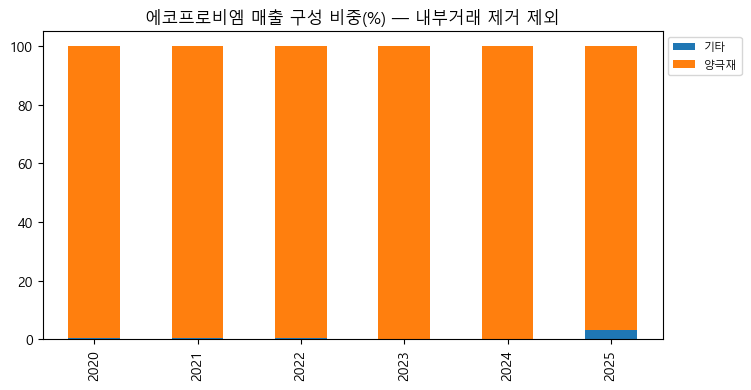

In [6]:
# 제품명 표기와 코드가 해마다 조금씩 바뀌므로, 괄호 안 설명과 "및 …"을 떼어 낸 이름으로 묶습니다.
import re
def base_name(n):
    n = re.sub(r"\(.*?\)|\(.*$", "", str(n)).strip()
    return n.split(" 및 ")[0].strip() or str(n)
annual = annual.assign(item=annual["product_name"].map(base_name))
tr = annual[annual["product_code"] != "99"].pivot_table(index="date", columns="item", values="sales_억", aggfunc="sum")
tr.index = tr.index.year
share = tr.div(tr.clip(lower=0).sum(axis=1), axis=0) * 100
print("연도별 매출(억원)")
display(tr.round(0))
ax = share.clip(lower=0).plot(kind="bar", stacked=True, figsize=(8, 4), title=f"{NAME} 매출 구성 비중(%) — 내부거래 제거 제외")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=8); _ = ax.set_xlabel("")

## 4. 관련 테마 태그
DeepSearch가 기업에 붙인 주제 태그 가운데 **해당(score=1)** 인 것만 고릅니다.

In [7]:
tags = ds_df(f"GetEntityTags({STOCK})")
hit = tags[tags["data"].apply(lambda d: isinstance(d, dict) and d.get("score") == 1)].copy()
hit["category"] = hit["category"].apply(lambda c: " ".join(c) if isinstance(c, list) else str(c))
for cat, g in hit.groupby("category"):
    print(cat, ":", ", ".join(g["name"]))

기업/재무지표 : 1인당 매출액 1억 이상, 유동비율 50% 이상, 영업이익 상위 10% 이상, 매출액 상위 10% 이상, 매출액총이익률 10% 이상, 자본 증가율 10% 이상, 순운전자본회전율 5배 이상, 당기순이익 상위 10% 이상, 매출액 증가율 상위 20%, 총자본순이익률(ROE) 10% 이상, 총자산증가율 상위 20%, 흑자, 총자본회전율 2배 이상, 제조업 EBITDA/매출비율 상위 20%, 당기순이익 증가율 10% 이상, 영업이익 증가율 상위 20%, 매출 지속 증가 기업, 자본 1조 이상
기업/재무지표 기업/주가지표 : 배당 지급
기업/주가지표 : 올해 주가변동성 1 미만, 최근 1년 주가 30% 이상 상승, 최근 1달 주가 20% 이상 상승


## 5. 같은 업종 상장사 (경쟁사 후보)
업종 분류(통계청 표준산업분류 세세분류, `industry_name`)가 같은 상장사를 시가총액 순으로 봅니다.

In [8]:
snap = all_stocks(ASOF)
me = snap[snap["symbol"] == STOCK].iloc[0]
peers = snap[snap["industry_id"] == me["industry_id"]].sort_values("market_cap", ascending=False)
print(f"업종: {me['industry_name']} — 상장사 {len(peers)}곳 (기준 {snap['date'].max().date()})")
out = peers[["name", "market", "close", "change_pct", "market_cap"]].head(10).copy()
out["시가총액"] = out["market_cap"].map(krw)
out.drop(columns="market_cap").round(2)

업종: 축전지 제조업 — 상장사 19곳 (기준 2026-11-24)


,name,market,close,change_pct,시가총액
189,LG에너지솔루션,KOSPI,314500,7.89,73.6조
1608,삼성SDI,KOSPI,450000,13.64,36.3조
1440,포스코퓨처엠,KOSPI,170400,12.92,15.2조
726,에코프로비엠,KOSDAQ,88400,11.34,9.5조
2517,엘앤에프,KOSPI,73500,11.20,3.0조
1582,DN오토모티브,KOSPI,37600,4.30,2.2조
880,에코프로머티,KOSPI,26850,11.41,1.9조
230,SK아이이테크놀로지,KOSPI,10720,1.61,"8,768억"
2468,피노,KOSDAQ,7080,14.19,"6,090억"
1673,세방전지,KOSPI,43450,2.48,"6,022억"


## 6. 점유율 언급 찾기 (대안)
점유율 수치는 DeepSearch에 구조화돼 있지 않습니다. 대신 **최근 1년 증권사 리포트·뉴스 가운데 이 회사가 태그되고 본문에 "점유율"이 나오는 문서**를 찾습니다.
제목에 "점유율 NN%"가 있으면 수치도 뽑아 둡니다. 리포트 PDF 본문은 스킬의 `read_document.py`로 읽을 수 있습니다.

In [9]:
import re
start = (pd.Timestamp(ASOF) - pd.DateOffset(years=1) + pd.Timedelta(days=1)).date()
for cat, label in (("research", "증권사 리포트"), ("news", "뉴스")):
    n, d = doc_search(cat, [], f"securities.name:{NAME} and 점유율", start, ASOF, count=50)
    d["점유율 수치"] = d["title"].str.findall(r"점유율[^0-9]{0,6}(\d+(?:\.\d+)?%)").str.join(", ")
    print(f"■ {label} {n}건 — 최근 5건")
    for _, r in d.head(5).iterrows():
        print(f"  {r['created_at']:%Y-%m-%d} [{r['publisher']}] {r['title']}")
    hits = d[d["점유율 수치"] != ""]
    if len(hits):
        print(f"  제목에 점유율 수치가 있는 문서 {len(hits)}건:")
        for _, r in hits.head(5).iterrows():
            print(f"    {r['created_at']:%Y-%m-%d} {r['점유율 수치']} — {r['title']}")
    print()

■ 증권사 리포트 6건 — 최근 5건
  2026-11-09 [iM증권] 양극재 출하 부진 지속
  2026-08-03 [iM증권] 올해 실적이 바닥, 밸류에이션 부담은 여전
  2026-07-29 [한국IR협의회] 수익성 정상화를 넘어 외형 확장 국면 진입
  2026-02-06 [메리츠종금증권] 4Q25 Review : 일회성 변수 반영되며 영업흑자 기록
  2026-02-06 [한화투자증권] 삼성SDI는 회복, SKon은 악화



■ 뉴스 50건 — 최근 5건
  2026-11-11 [지디넷코리아] 에코프로비엠, LFP 본격 참전…수주 속도·캐파 확대 관건
  2026-11-09 [뉴시스] iM證 "에코프로비엠 목표주가 하향…양극재 출하 부진 지속"
  2026-08-03 [매경이코노미] “도대체 바닥이 어디일까”…에코프로비엠 목표가 줄하향 [오늘, 이 종목]
  2026-07-15 [한국경제TV] 에코프로 1.2조 유증 막혔다…축소 대신 주주 설득
  2026-07-06 [문화일보] 에코프로비엠 창사 10년…“印尼 니켈 투자로 또 다른 10년 준비”



## 결과 읽는 법과 한계
- 매출 구성의 제품명은 사업보고서 표기를 20자 안팎에서 자른 것입니다(예: `DRAM,NAND Flash,모바일AP 등(제`).
- 최신 연간이 없으면 분기 누적(`accounting_type` 4·2·5)을 쓰면 됩니다. 분기 누적은 1월부터 그 분기까지의 합계입니다.
- **시장 점유율 수치는 없습니다.** 리포트·뉴스 검색은 근거 문서를 찾는 용도이고, 수치는 본문에서 확인해야 합니다. 제목에 나온 점유율은 회사 전체가 아니라 특정 시장(예: 중동 스마트폰) 기준인 경우가 많습니다.
- 같은 업종 상장사는 표준산업분류가 같은 회사라 실제 경쟁사와 다를 수 있습니다(예: 지주사·다각화 기업).